In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import os

In [17]:
# === Load CSV ===\
df = pd.read_csv('dataset\sales_data.csv', parse_dates=['Date'])

In [18]:
# === Create output folder ===
os.makedirs('output', exist_ok=True)

In [19]:
# === Initial Inspection ===
print("First 5 Records:\n", df.head())
print("\nMissing Values:\n", df.isnull().sum())
print("\nData Summary:\n", df.describe(include='all'))

First 5 Records:
         Date Region    Product  Quantity  Unit_Price  Total_Sales
0 2023-01-01  North  Product A        10          20          200
1 2023-01-02  North  Product B         5          15           75
2 2023-01-03  South  Product A         7          20          140
3 2023-01-04   East  Product C         8          25          200
4 2023-01-05   West  Product A         9          20          180

Missing Values:
 Date           0
Region         0
Product        0
Quantity       0
Unit_Price     0
Total_Sales    0
dtype: int64

Data Summary:
                        Date Region    Product   Quantity  Unit_Price  \
count                    13     13         13  13.000000   13.000000   
unique                  NaN      4          3        NaN         NaN   
top                     NaN  North  Product A        NaN         NaN   
freq                    NaN      4          5        NaN         NaN   
mean    2023-01-07 00:00:00    NaN        NaN   7.538462   20.000000   
min  

In [20]:
# === AGGREGATIONS ===

# Total Sales by Region
region_sales = df.groupby("Region")["Total_Sales"].sum().reset_index()

# Total Sales Over Time
time_sales = df.groupby("Date")["Total_Sales"].sum().reset_index()

# Top-Selling Products
top_products = df.groupby("Product")["Total_Sales"].sum().sort_values(ascending=False).reset_index()


In [21]:
# === Handling Missing Data ===
df = df.dropna(subset=['Total_Sales'])          # Drop rows where Total_Sales is missing
df['Region'] = df['Region'].fillna('Unknown')   # Fill missing regions with 'Unknown'
df['Product'] = df['Product'].fillna('Misc')    # Fill missing products
df['Category'] = df.get('Category', 'General')  # Safely create or access Category
df['Category'] = df['Category'].fillna('General')


In [22]:
# === Additional Date Features ===
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month_name()
df['Weekday'] = df['Date'].dt.day_name()


In [23]:
# === Aggregated Metrics ===
region_sales = df.groupby("Region")["Total_Sales"].sum().reset_index()
time_sales = df.groupby("Date")["Total_Sales"].sum().reset_index()
product_sales = df.groupby("Product")["Total_Sales"].sum().sort_values(ascending=False).reset_index()
category_sales = df.groupby("Category")["Total_Sales"].sum().reset_index()
monthly_trend = df.groupby("Month")["Total_Sales"].sum().reindex(
    ['January', 'February', 'March', 'April', 'May', 'June',
     'July', 'August', 'September', 'October', 'November', 'December']
).reset_index()
weekday_trend = df.groupby("Weekday")["Total_Sales"].sum().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
).reset_index()

In [24]:
# === Cumulative Sales ===
df = df.sort_values(by='Date')
df['Cumulative_Sales'] = df['Total_Sales'].cumsum()

In [25]:
# === Top Customers (if available) ===
top_customers = df.groupby("Customer_Name")["Total_Sales"].sum().sort_values(ascending=False).reset_index().head(10) if 'Customer_Name' in df.columns else pd.DataFrame()


In [26]:
# === Correlation Analysis ===
correlation_matrix = df.select_dtypes(include='number').corr()

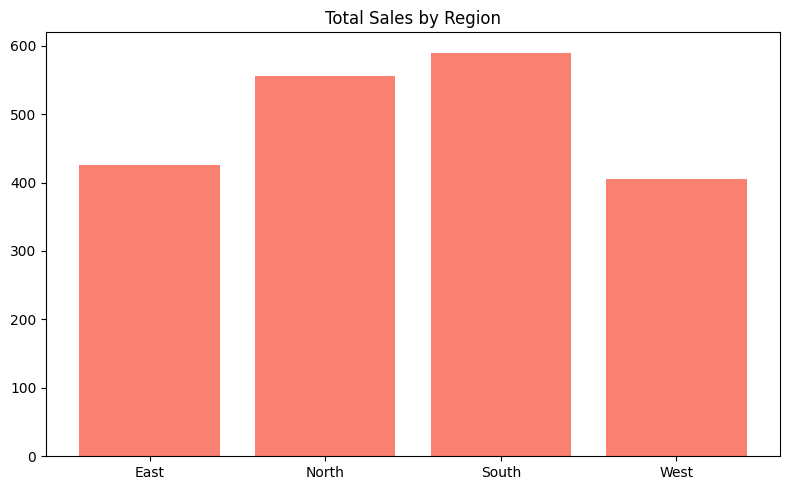

In [27]:
# === Static Charts ===
plt.figure(figsize=(8, 5))
plt.bar(region_sales['Region'], region_sales['Total_Sales'], color='salmon')
plt.title("Total Sales by Region")
plt.tight_layout()
plt.savefig("output/sales_by_region.png")
plt.show()

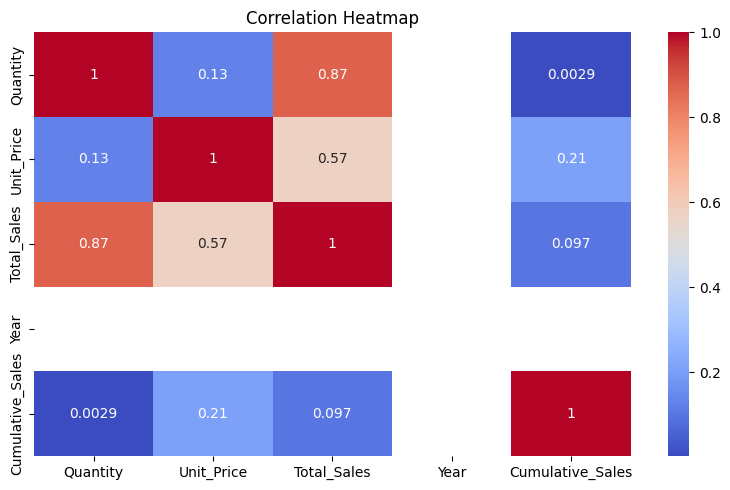

In [28]:
plt.figure(figsize=(8, 5))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("output/correlation_heatmap.png")
plt.show()

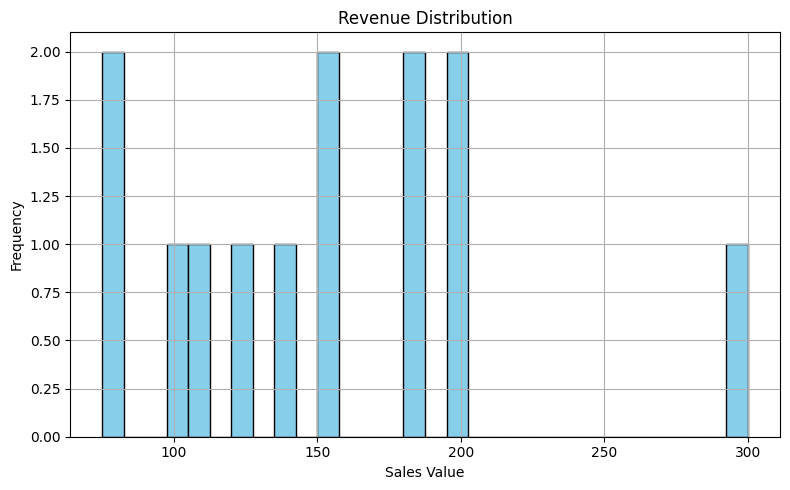

In [29]:
plt.figure(figsize=(8, 5))
df['Total_Sales'].hist(bins=30, color='skyblue', edgecolor='black')
plt.title("Revenue Distribution")
plt.xlabel("Sales Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("output/revenue_distribution.png")
plt.show()

In [31]:
# === Interactive Charts ===
fig1 = px.line(df, x='Date', y='Cumulative_Sales', title='Cumulative Sales Over Time')
fig2 = px.bar(product_sales.head(10), x='Product', y='Total_Sales', title='Top 10 Products')
fig3 = px.pie(category_sales, names='Category', values='Total_Sales', title='Sales by Category')
fig4 = px.line(monthly_trend, x='Month', y='Total_Sales', title='Monthly Sales Trend')
fig5 = px.bar(weekday_trend, x='Weekday', y='Total_Sales', title='Weekday Sales Trend')

fig1.show()
fig2.show()
fig3.show()
fig4.show()
fig5.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [ ]:
# === VISUALIZATION: Matplotlib (Static) ===

plt.figure(figsize=(8, 5))
plt.bar(region_sales['Region'], region_sales['Total_Sales'], color='skyblue')
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("region_sales.png")
plt.show()

In [ ]:
# === VISUALIZATION: Plotly (Interactive) ===

# Sales Over Time Line Chart
fig1 = px.line(time_sales, x='Date', y='Total_Sales', title='Total Sales Over Time')
fig1.show()

# Top-Selling Products Bar Chart
fig2 = px.bar(top_products, x='Product', y='Total_Sales', title='Top-Selling Products')
fig2.show()

In [ ]:
# === Export CSV of Top Products ===
product_sales.head(10).to_csv("output/top_10_products.csv", index=False)

print("\n✅ Enhanced analytics completed. Charts and reports saved in the 'output/' folder.")